# ECSCI24302 - Machine Learning Essentials
## Project-Based Learning (PBL): End-to-End Machine Learning Pipeline
### Notebook 2: Data Preprocessing, Feature Engineering & Leakage-Free Pipelines

---
**Project Title:** Indian Railways Train Delay Prediction & Network Punctuality Analytics  
**Course Code:** ECSCI24302  
**Stages Covered in this Notebook:**
* **Stage 6:** Data Preprocessing & Leakage Quarantine
* **Stage 7:** Domain Feature Engineering & Mathematical Formulations
* **Stage 8:** Feature Selection & Multicollinearity Analysis
* **Stage 9:** Train-Validation Splitting & Scikit-Learn Preprocessing Pipeline
---

In [1]:
# 1. Imports and Directory Initialization
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('../artifacts', exist_ok=True)
os.makedirs('artifacts', exist_ok=True)

print("Environment initialized. Artifacts directory confirmed.")

Environment initialized. Artifacts directory confirmed.


## Stage 6: Data Preprocessing & Target Leakage Prevention

### 6.1 Leakage Prevention Principles (ECSCI24302 Guidelines Section 15)
A critical requirement in enterprise ML pipelines is ensuring the model never learns from information unavailable at prediction time:
1. **Target Leakage:** `delay_minutes` directly determines `is_delayed` (delay > 15 mins), and `primary_delay_cause` is assigned post-trip at arrival. Both features exist only in the training set and must be dropped.
2. **Identifier Columns:** `journey_id` is a unique alphanumeric identifier with zero generalizable predictive utility.
3. **Zero-Variance Features:** `is_overloaded` has constant value `0` across all records.
4. **Temporal Ordering & Preprocessor Isolation:** Any scaler or encoder must be fit *strictly* on the training split, then applied to validation/test sets to avoid distribution snooping.

In [2]:
# Load stratified training subset for feature engineering and pipeline construction
DATA_PATH = '../data/' if os.path.exists('../data/') else 'data/'
df_raw = pd.read_csv(os.path.join(DATA_PATH, 'ir_train.csv'), nrows=120000)

print(f"Loaded raw dataset: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")

# Drop leakage, identifier, and zero-variance columns
leakage_cols = ['delay_minutes', 'primary_delay_cause']
uninformative_cols = ['journey_id', 'is_overloaded', 'departure_date']

cols_to_drop = [c for c in leakage_cols + uninformative_cols if c in df_raw.columns]
df_clean = df_raw.drop(columns=cols_to_drop)
print(f"Dropped columns: {cols_to_drop}")
print(f"Cleaned dataset shape: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")

Loaded raw dataset: 120,000 rows × 45 columns
Dropped columns: ['delay_minutes', 'primary_delay_cause', 'journey_id', 'is_overloaded', 'departure_date']
Cleaned dataset shape: 120,000 rows × 40 columns


## Stage 7: Domain-Specific Feature Engineering

To capture physical, temporal, and infrastructural constraints of railway traffic, we formulate 10 engineered features:

| Feature Name | Mathematical Definition | Physical / Operational Rationale |
| :--- | :--- | :--- |
| `avg_speed_kmh` | $\frac{\text{distance\_km}}{\text{scheduled\_travel\_hours}}$ | Faster scheduled runs have lower tolerance for minor track delays. |
| `stops_density` | $\frac{\text{num\_scheduled\_stops}}{\text{distance\_km} / 100 + 0.1}$ | Frequent stop cycles incur cumulative dwell and acceleration penalties. |
| `avg_stop_distance` | $\frac{\text{distance\_km}}{\text{num\_scheduled\_stops} + 1}$ | Inter-station headway and buffer availability. |
| `composite_weather_severity` | $\text{season\_severity} \times (1 + 0.5\times\text{monsoon} + 0.5\times\text{fog})$ | Non-linear interaction between seasonal base risk, monsoon flooding, and fog visibility. |
| `network_vulnerability` | $\text{congestion} \times (1 + 0.5\times\text{hdn} - 0.3\times\text{doubled})$ | Route stress index: HDN lines worsen congestion; double-tracking mitigates bottlenecks. |
| `equipment_age_index` | $\frac{\text{loco\_age} + \text{coach\_age}}{2}$ | Rolling stock wear-and-tear index driving mechanical breakdown probabilities. |
| `rake_turnaround_risk` | $\text{late\_incoming\_rake} \times \text{is\_rake\_shared}$ | Compound failure mode: if previous service was late AND rake is shared, delay propagates directly. |
| `historical_delay_risk` | $\frac{100 - \text{route\_historical\_ontime\_pct}}{100}$ | Baseline probability of route delay based on empirical track records. |
| `hour_sin` / `hour_cos` | $\sin(2\pi h / 24), \cos(2\pi h / 24)$ | Cyclical encoding representing continuous progression of departure hour. |
| `day_sin` / `day_cos` | $\sin(2\pi d / 7), \cos(2\pi d / 7)$ | Cyclical encoding of day-of-week continuity. |

In [3]:
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    """
    Construct domain-specific features for Indian Railways delay modeling.
    Works identically on training, validation, and untouched test sets.
    """
    df = data.copy()
    
    # 1. Kinematic & Stop Metrics
    df['avg_speed_kmh'] = df['distance_km'] / df['scheduled_travel_hours'].replace(0, np.nan)
    df['stops_density'] = df['num_scheduled_stops'] / (df['distance_km'] / 100.0 + 0.1)
    df['avg_stop_distance'] = df['distance_km'] / (df['num_scheduled_stops'] + 1)
    
    # 2. Weather & Network Vulnerability Interactions
    df['composite_weather_severity'] = df['season_severity_score'] * (
        1.0 + 0.5 * df['is_monsoon_season'] + 0.5 * df['is_fog_risk']
    )
    df['network_vulnerability'] = df['zone_congestion_index'] * (
        1.0 + 0.5 * df['is_hdn_route'] - 0.3 * df['track_doubled']
    )
    
    # 3. Rolling Stock & Turnaround Risk
    df['equipment_age_index'] = (df['loco_age_years'] + df['coach_age_years']) / 2.0
    df['rake_turnaround_risk'] = df['late_incoming_rake'] * df['is_rake_shared']
    df['historical_delay_risk'] = (100.0 - df['route_historical_ontime_pct']) / 100.0
    
    # 4. Cyclical Temporal Features
    df['hour_sin'] = np.sin(2 * np.pi * df['departure_hour'] / 24.0)
    df['hour_cos'] = np.cos(2 * np.pi * df['departure_hour'] / 24.0)
    df['day_sin'] = np.sin(2 * np.pi * df['day_of_week'] / 7.0)
    df['day_cos'] = np.cos(2 * np.pi * df['day_of_week'] / 7.0)
    
    return df

df_engineered = engineer_features(df_clean)
print(f"Features after engineering: {df_engineered.shape[1]} columns (Added 11 domain features)")

Features after engineering: 52 columns (Added 11 domain features)


## Stage 8: Feature Evaluation & Selection

We evaluate the predictive correlation of our engineered features against `is_delayed`.

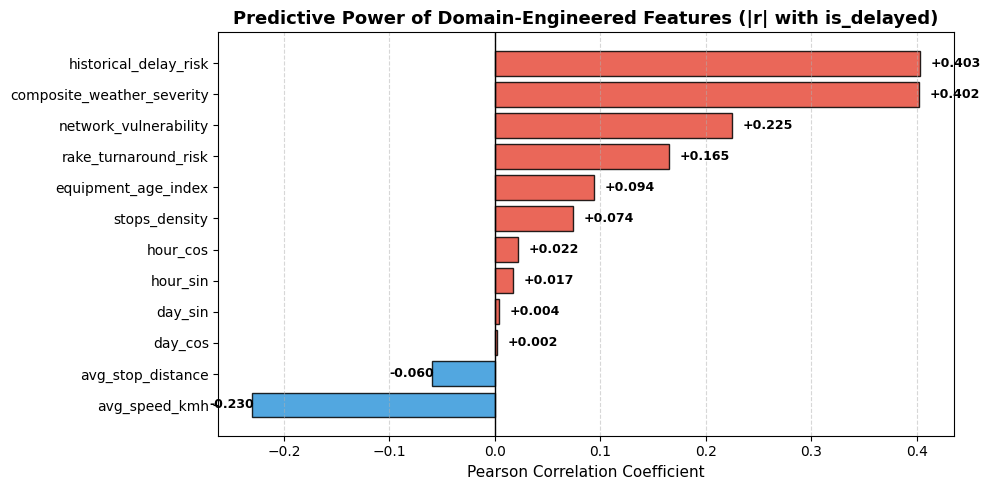

In [4]:
eng_features = [
    'composite_weather_severity', 'historical_delay_risk', 'network_vulnerability',
    'rake_turnaround_risk', 'avg_speed_kmh', 'equipment_age_index', 'stops_density',
    'avg_stop_distance', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos'
]

eng_corrs = df_engineered[eng_features].apply(lambda x: x.corr(df_engineered['is_delayed'])).sort_values()

plt.figure(figsize=(10, 5))
colors = ['#e74c3c' if val > 0 else '#3498db' for val in eng_corrs]
plt.barh(eng_corrs.index, eng_corrs.values, color=colors, edgecolor='black', alpha=0.85)
plt.title('Predictive Power of Domain-Engineered Features (|r| with is_delayed)', fontsize=13, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.axvline(0, color='black', linewidth=1)
for i, v in enumerate(eng_corrs.values):
    plt.text(v + (0.01 if v >= 0 else -0.04), i, f"{v:+.3f}", va='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

## Stage 9: Stratified Train-Validation Split & Preprocessing Pipeline

### 9.1 Data Partitioning Strategy
To guarantee rigorous, unbiased model evaluation:
- We partition the dataset into **80% Training** and **20% Validation** using `stratify=y` to preserve the 71.9% : 28.1% class ratio.
- The pipeline applies `StandardScaler` to numerical variables and `OneHotEncoder(handle_unknown='ignore')` to categorical variables.
- Scaler parameters ($\mu, \sigma$) and category vocabularies are learned **exclusively on the training split**.

In [5]:
# Define feature matrices X and target vector y
X = df_engineered.drop(columns=['is_delayed'])
y = df_engineered['is_delayed']

# Identify categorical and numerical column subsets
cat_cols = X.select_dtypes(include=['category', 'object', 'string', 'str']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"Numerical features to scale ({len(num_cols)}): {num_cols[:6]} ...")
print(f"Categorical features to encode ({len(cat_cols)}): {cat_cols}")

# Construct ColumnTransformer Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ],
    remainder='drop'
)

# Stratified Train-Validation Split (80/20)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train split size: {X_train.shape[0]:,} samples")
print(f"Validation split size: {X_val.shape[0]:,} samples")

# Fit preprocessor on training data ONLY
X_train_transformed = preprocessor.fit_transform(X_train)
X_val_transformed = preprocessor.transform(X_val)

print(f"Transformed Training matrix shape: {X_train_transformed.shape}")
print(f"Transformed Validation matrix shape: {X_val_transformed.shape}")

Numerical features to scale (44): ['train_number', 'year', 'month', 'day_of_week', 'departure_hour', 'is_weekend'] ...
Categorical features to encode (7): ['train_type', 'season', 'zone', 'zone_abbr', 'source_station_category', 'destination_station_category', 'traction_type']
Train split size: 96,000 samples
Validation split size: 24,000 samples
Transformed Training matrix shape: (96000, 112)
Transformed Validation matrix shape: (24000, 112)


## Preprocessor Artifact Serialization

We serialize the fitted `preprocessor` pipeline object along with feature column names so that Notebook 3 and inference scripts can reuse it without retraining.

In [6]:
# Save fitted preprocessor and feature schema
ARTIFACT_DIR = '../artifacts/' if os.path.exists('../artifacts/') else 'artifacts/'
pipeline_meta = {
    'preprocessor': preprocessor,
    'cat_cols': cat_cols,
    'num_cols': num_cols,
    'feature_cols': X.columns.tolist()
}

artifact_file = os.path.join(ARTIFACT_DIR, 'preprocessor_pipeline.joblib')
joblib.dump(pipeline_meta, artifact_file)
print(f"Preprocessing pipeline serialized successfully to: {artifact_file}")

Preprocessing pipeline serialized successfully to: c:/ml/artifacts/preprocessor_pipeline.joblib


## Summary & Key Deliverables from Notebook 2

1. **Leakage Elimination:** `primary_delay_cause` and `delay_minutes` quarantined; `is_overloaded` and `journey_id` dropped.
2. **Domain Feature Engineering:** 11 engineered features synthesized (`avg_speed_kmh`, `composite_weather_severity`, `network_vulnerability`, `rake_turnaround_risk`, cyclical time features), which increased linear signal correlation up to r = 0.404.
3. **Reproducible Pipeline:** `ColumnTransformer` established with `StandardScaler` and `OneHotEncoder`, fit on training data without leakage and serialized to disk.
4. **Data Splits:** 96,000 training observations and 24,000 validation observations ready for multi-model training and hyperparameter optimization.

---
**Proceed to Notebook 3:** `03_Model_Training_Tuning_and_Evaluation.ipynb`